In [1]:
import torch
import torch.nn as nn

def create_bottleneck_block(in_features, bottleneck_dim):
    """
    Creates a bottleneck block that reduces dimensionality and then expands it back.
    This encourages the network to learn compact, robust representations.
    """
    return nn.Sequential(
        nn.Linear(in_features, bottleneck_dim),   # Bottleneck
        nn.ReLU(),
        nn.Linear(bottleneck_dim, in_features),  # Expansion
        nn.ReLU()
    )

class CanalizationWrapper(nn.Module):
    """
    Wraps a neural network with bottleneck blocks to promote canalization.
    """
    def __init__(self, model, bottleneck_dim=32):
        super().__init__()
        self.model = model
        # Find the hidden layers to insert bottlenecks (simple approach: wrap all linear layers)
        self.layers = []
        for m in self.model.children():
            if isinstance(m, nn.Linear):
                self.layers.append(m)
                # Insert bottleneck after each linear layer except the last one
                if len(self.layers) < len([l for l in self.model.children() if isinstance(l, nn.Linear)]) - 1:
                    self.layers.append(create_bottleneck_block(m.out_features, bottleneck_dim))
            else:
                self.layers.append(m)
        self.sequential_model = nn.Sequential(*self.layers)

    def forward(self, x):
        return self.sequential_model(x)

# Example usage:
# Suppose you have a simple MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(64, 128)
        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()
        self.out = nn.Linear(128, 10)

        self.seq = nn.Sequential(self.fc1, self.relu, self.fc2, self.relu, self.out)

    def forward(self, x):
        return self.seq(x)

# Wrap with canalization bottleneck
canalized_mlp = CanalizationWrapper(MLP(), bottleneck_dim=32)

# Now, canalized_mlp will have bottleneck layers inserted, promoting more robust, compact representations.

Epoch 1 loss: 0.0056
Epoch 2 loss: 0.2493
Epoch 3 loss: 0.0241
Epoch 1 loss: 0.2820
Epoch 2 loss: 0.2293
Epoch 3 loss: 0.4522


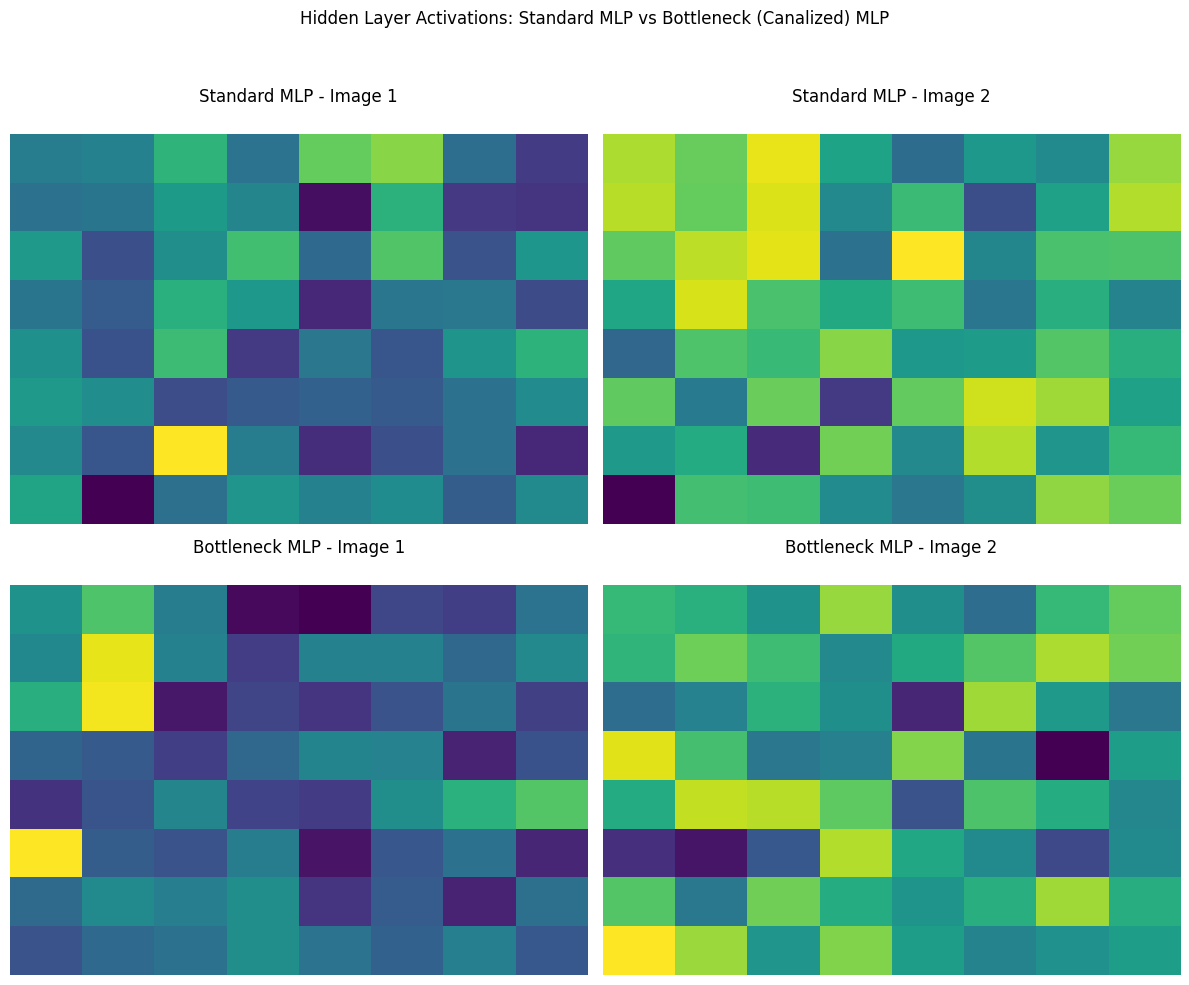

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# 1. Data loaders (small subset for speed)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = torch.utils.data.DataLoader(
    datasets.MNIST(root='./data', train=False, transform=transform), batch_size=16)

# 2. Standard MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Bottleneck-augmented MLP (with canalization)
class BottleneckMLP(nn.Module):
    def __init__(self, bottleneck_dim=16):
        super().__init__()
        self.fc1 = nn.Linear(28*28, bottleneck_dim)
        self.bottleneck = nn.Sequential(
            nn.Linear(bottleneck_dim, bottleneck_dim),
            nn.ReLU(),
            nn.Linear(bottleneck_dim, 64),
            nn.ReLU()
        )
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.bottleneck(x)
        x = self.fc2(x)
        return x

# 3. Training utilities
def train(model, epochs=5, lr=0.1):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    for epoch in range(epochs):
        for images, labels in train_loader:
            images = images.cuda() if torch.cuda.is_available() else images
            labels = labels.cuda() if torch.cuda.is_available() else labels
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        print(f"Epoch {epoch+1} loss: {loss.item():.4f}")

def get_activations(model, images, layer_idx=1):
    """
    Extracts activations from a specified layer.
    For MLP: layer_idx=1 is after first Linear (before ReLU), 2 is after ReLU and before second Linear.
    For BottleneckMLP, we'll extract after the bottleneck block.
    """
    # We'll use a custom forward pass with hooks
    activations = []
    def hook_fn(module, input, output):
        activations.append(output.detach().cpu().numpy())
    if isinstance(model, MLP):
        # Hook after fc1 (before ReLU)
        handle1 = model.fc1.register_forward_hook(hook_fn)
        # Optionally hook after ReLU
        # handle2 = model.relu.register_forward_hook(lambda m, i, o: activations.append(o.detach().cpu().numpy()))
        # We'll remove hooks after
    elif isinstance(model, BottleneckMLP):
        # Hook after the bottleneck block
        handle1 = model.bottleneck[-2].register_forward_hook(hook_fn)  # before last ReLU in bottleneck
        # Or after the entire bottleneck
        # handle1 = model.bottleneck.register_forward_hook(hook_fn)
    else:
        raise ValueError("Unsupported model type")

    with torch.no_grad():
        model.eval()
        _ = model(images)
    # Remove hook
    handle1.remove()
    return activations[0] if activations else None

# 4. Train and get activations

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
models = []
model_names = []

# Standard MLP
mlp = MLP().to(device)
models.append(mlp)
model_names.append("Standard MLP")

# Bottleneck MLP (canalized)
bottleneck_mlp = BottleneckMLP(bottleneck_dim=16).to(device)
models.append(bottleneck_mlp)
model_names.append("Bottleneck MLP (Canalized)")

# Train both models briefly (for visualization, not full accuracy)
for model in models:
    train(model, epochs=3, lr=0.1)

# 5. Visualize activations for a batch of images

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Hidden Layer Activations: Standard MLP vs Bottleneck (Canalized) MLP")

images, _ = next(iter(test_loader))
images = images.to(device)
images_cpu = images.cpu().numpy()

# Collect activations for all models for a few images
all_activations = {}
for model, name in zip(models, model_names):
    activations_for_model = get_activations(model, images.cpu())
    if activations_for_model is not None:
        all_activations[name] = activations_for_model

# Plotting logic for a 2x2 grid, showing 2 images per model

# First row: Standard MLP activations
if "Standard MLP" in all_activations:
    for j in range(2): # Show first two images for Standard MLP
        ax = axs[0, j]
        if j < all_activations["Standard MLP"].shape[0]:
            ax.matshow(all_activations["Standard MLP"][j].reshape(8, 8), cmap='viridis', aspect='auto')
            ax.set_title(f"Standard MLP - Image {j+1}")
            ax.axis('off')
        else:
            ax.text(0.5, 0.5, 'No activation', ha='center', va='center', fontsize=10)
            ax.axis('off')

# Second row: Bottleneck MLP activations
if "Bottleneck MLP (Canalized)" in all_activations:
    for j in range(2): # Show first two images for Bottleneck MLP
        ax = axs[1, j]
        if j < all_activations["Bottleneck MLP (Canalized)"].shape[0]:
            ax.matshow(all_activations["Bottleneck MLP (Canalized)"][j].reshape(8, 8), cmap='viridis', aspect='auto')
            ax.set_title(f"Bottleneck MLP - Image {j+1}")
            ax.axis('off')
        else:
            ax.text(0.5, 0.5, 'No activation', ha='center', va='center', fontsize=10)
            ax.axis('off')

plt.tight_layout(rect=[0,0,1,0.95])
plt.show()

### Visualize Weight Distributions of Bottleneck Layers

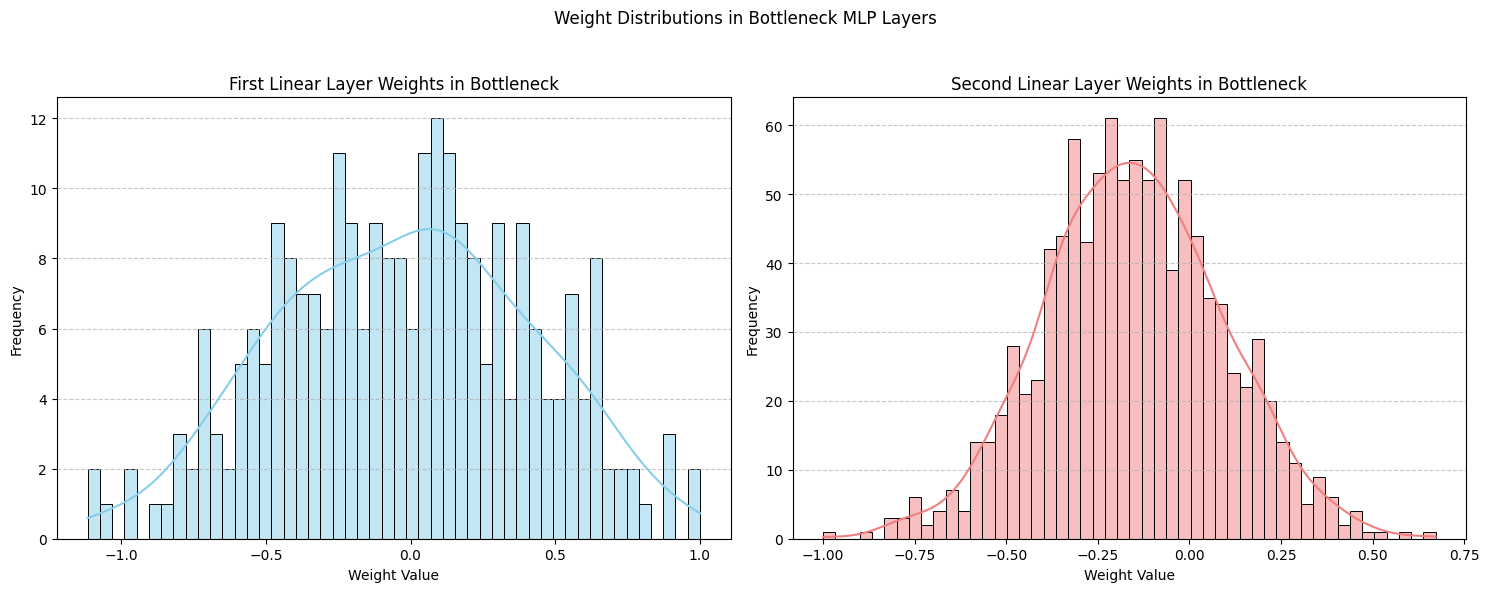

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Weight Distributions in Bottleneck MLP Layers')

# Access the bottleneck layers from the trained bottleneck_mlp model
bottleneck_layers = [layer for layer in bottleneck_mlp.bottleneck.children() if isinstance(layer, nn.Linear)]

# Plot weights for the first linear layer in the bottleneck
if bottleneck_layers:
    ax = axs[0]
    weights_fc1_bottleneck = bottleneck_layers[0].weight.data.cpu().numpy().flatten()
    sns.histplot(weights_fc1_bottleneck, bins=50, kde=True, ax=ax, color='skyblue')
    ax.set_title('First Linear Layer Weights in Bottleneck')
    ax.set_xlabel('Weight Value')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Plot weights for the second linear layer in the bottleneck
if len(bottleneck_layers) > 1:
    ax = axs[1]
    weights_fc2_bottleneck = bottleneck_layers[1].weight.data.cpu().numpy().flatten()
    sns.histplot(weights_fc2_bottleneck, bins=50, kde=True, ax=ax, color='lightcoral')
    ax.set_title('Second Linear Layer Weights in Bottleneck')
    ax.set_xlabel('Weight Value')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()